# Train CNN on U-VNE data
- We used multilabel dataset to run this script.

In [ ]:
import IPython.display as display
from IPython.display import display   

from PIL import Image

import numpy as np
import matplotlib.pyplot as plt
import pathlib
import pandas as pd
import re
import seaborn as sns
import random
import umap

from sklearn.metrics import pairwise_distances, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from collections import Counter


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
#from tensorflow.keras.saving import register_keras_serializable
from tensorflow.keras.callbacks import ModelCheckpoint

from tensorflow.keras.utils import register_keras_serializable
import tensorflow.keras.backend as K

%env CUDA_DEVICE_ORDER=PCI_BUS_ID
%env CUDA_VISIBLE_DEVICES=1

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1" # Disable GPU

AUTOTUNE = tf.data.experimental.AUTOTUNE

tf.__version__
tf.keras.__file__

env: CUDA_DEVICE_ORDER=PCI_BUS_ID
env: CUDA_VISIBLE_DEVICES=1


'c:\\Users\\Acer\\Desktop\\TSI\\U_VNE_CNN\\venv\\Lib\\site-packages\\keras\\_tf_keras\\keras\\__init__.py'

In [5]:
# use Metropolis when it needed
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager as font_manager

font_path = r"C:/Users/Acer/AppData/Local/Microsoft/Windows/Fonts/"

metropolis_fonts = {
    "regular": "Metropolis-Regular.otf",
    "bold": "Metropolis-Bold.otf",
    "semibold": "Metropolis-SemiBold.otf",
    "light": "Metropolis-Light.otf",
    "medium": "Metropolis-Medium.otf",
    "black": "Metropolis-Black.otf",
    "extrabold": "Metropolis-ExtraBold.otf",
    "italic": "Metropolis-RegularItalic.otf"
}

# dictionary for FontProperties
metro = {}

for style, filename in metropolis_fonts.items():
    fullpath = os.path.join(font_path, filename)
    if os.path.exists(fullpath):
        font_manager.fontManager.addfont(fullpath)
        metro[style] = FontProperties(fname=fullpath)
    else:
        print(f"⚠️ Not found {filename}")

# 0. Basic setup

In [6]:
#OUTPUTS

# PATHS TO SAVE MODEL (.keras)
SAVE_DIR_K_1 = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_135_1"
SAVE_DIR_K_2 = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_135_2"

BEST_MODEL_PATH_K_1 = os.path.join(SAVE_DIR_K_1, "best_model_finetuned.keras")
BEST_MODEL_PATH_K_2 = os.path.join(SAVE_DIR_K_2, "best_model_finetuned.keras")

# PATH TO SAVE PLOTS
PLOT_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\plots"


print("✅ Training phase 1 will be saved at:")
print(BEST_MODEL_PATH_K_1)
print("✅ Training phase 2 will be saved at:")
print(BEST_MODEL_PATH_K_2)
print("✅ Plots will be saved at:")
print()

✅ Training phase 1 will be saved at:
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_135_1\best_model_finetuned.keras
✅ Training phase 2 will be saved at:
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_135_2\best_model_finetuned.keras
✅ Plots will be saved at:



In [7]:
# INPUTS

# MEL SPECTROGRAMS
MELS_TRVAL_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb"


# LABELS
ORG_AUG_LABELS_TR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_df_org_aug_pb.csv"
ORG_LABELS_VAL = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\val_df_pb.csv"

# READ LABELS
train_df = pd.read_csv(ORG_AUG_LABELS_TR)
if "aug" in train_df.columns:
    train_df = train_df.drop(columns=["aug"])
val_df = pd.read_csv(ORG_LABELS_VAL)

print("✅ train_df")
display(train_df.sample(5))

print("✅ val_df")
display(val_df.sample(5))


✅ train_df


,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI
5095,007_61_P1_AUG_STS.wav,0,0,0,0,0,0,0,0,1
3931,002_14_P1_AUG_PNS.wav,1,0,1,0,0,0,0,0,0
13894,075_80_P2_AUG_PPS.wav,0,0,0,0,0,0,0,0,1
12317,065_82_P1_AUG_NPS.wav,1,0,0,0,1,0,0,0,0
362,011_26_P1.wav,1,0,0,0,0,0,0,0,0


✅ val_df


,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI
771,085_45_P1.wav,1,0,0,0,0,0,0,0,0
603,068_73_P1.wav,0,1,1,0,0,0,0,0,0
268,029_73_P2.wav,0,0,0,0,0,0,0,0,1
299,032_86_P2.wav,0,1,1,0,0,0,0,0,0
216,024_45_P2.wav,0,1,1,0,0,0,0,0,0


In [8]:
# extensions: wav to png

train_df["png_filename"] = train_df["filename"].str.replace(".wav", ".png", regex=False)
val_df["png_filename"] = val_df["filename"].str.replace(".wav", ".png", regex=False)

print("✅ train_df")
display(train_df.sample(5, random_state=42))

print("✅ val_df")
display(val_df.sample(5, random_state=42))

✅ train_df


,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,png_filename
15176,080_42_P2_AUG_DLY.wav,1,0,0,0,0,0,0,1,0,080_42_P2_AUG_DLY.png
14830,078_71_P2_AUG_TND.wav,1,0,0,0,1,0,0,0,0,078_71_P2_AUG_TND.png
5133,009_07_P1_AUG_DLY.wav,0,0,0,0,0,0,0,1,0,009_07_P1_AUG_DLY.png
4116,002_63_P2_AUG_PNS.wav,0,0,0,0,0,0,0,1,0,002_63_P2_AUG_PNS.png
8903,036_59_P2_AUG_NPS.wav,0,1,1,0,0,0,0,0,0,036_59_P2_AUG_NPS.png


✅ val_df


,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,png_filename
199,022_01_P2.wav,0,1,0,0,0,0,0,0,0,022_01_P2.png
929,100_06_P2.wav,0,0,1,0,0,0,0,0,0,100_06_P2.png
693,077_66_P1.wav,0,0,0,0,1,0,0,0,0,077_66_P1.png
798,087_63_P2.wav,1,0,0,0,0,0,0,0,0,087_63_P2.png
874,095_02_P1.wav,0,1,1,0,0,0,0,0,0,095_02_P1.png


In [9]:
CLASS_NAMES = ["TM","MH","VO","MU","EM","SO","BI","GE","SI"]
N_CLASSES = len(CLASS_NAMES)
N_CLASSES

9

In [26]:
# CLASS WEIGHTS

CLASS_COUNTS = train_df[CLASS_NAMES].sum().values
TOTAL_COUNT = CLASS_COUNTS.sum()
N_CLASSES

alpha = TOTAL_COUNT / (N_CLASSES * CLASS_COUNTS)
alpha = alpha.astype(np.float32)

print("✅ Class weights (alpha):")
for c, w in zip(CLASS_NAMES, alpha):
    print(f"{c}: {w:.4f}")

✅ Class weights (alpha):
TM: 0.4506
MH: 0.8460
VO: 0.4239
MU: 1.4754
EM: 1.4149
SO: 5.8539
BI: 2.9035
GE: 1.6000
SI: 1.3985


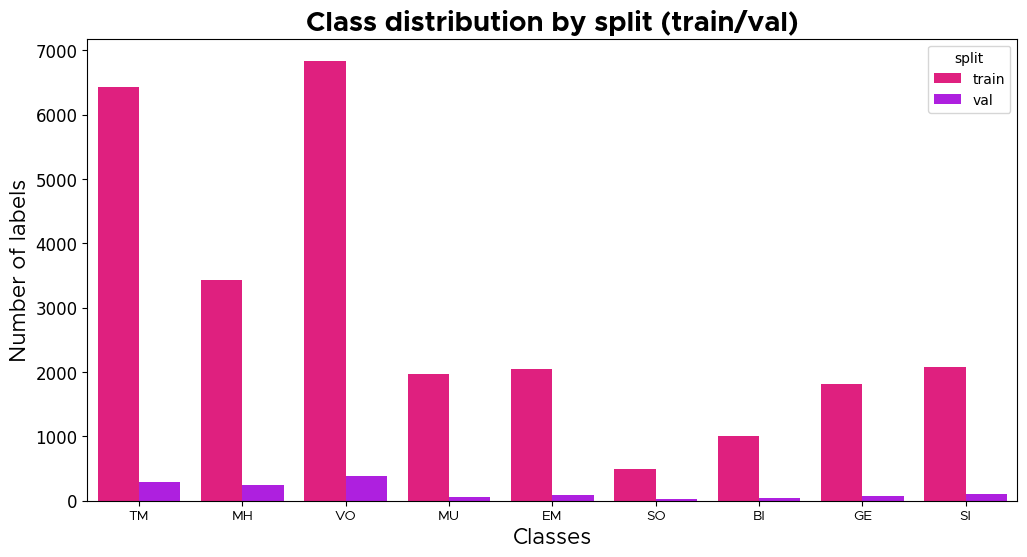

In [27]:
# CLASS DISTRIBUTION BY SPLIT

# add the 'split' column to concatenate train and val

train_df["split"] = "train"
val_df["split"]   = "val"

full = pd.concat([train_df, val_df], ignore_index=True)

# plot class distribution

fig, ax = plt.subplots(1, 1, figsize=(12, 6))

count_data = full.melt(
    id_vars="split",
    value_vars=CLASS_NAMES,
    var_name="Class",
    value_name="Present"
)
count_data = count_data[count_data["Present"] == 1]

sns.countplot(
    data=count_data,
    x="Class",
    hue="split",
    ax=ax,
    palette=["#ff007f", "#bd00ff"]
)

ax.set_xlabel("Classes", fontproperties=metro["regular"], fontsize=16)
ax.set_ylabel("Number of labels", fontproperties=metro["regular"], fontsize=16)
ax.set_title(
    "Class distribution by split (train/val)",
    fontproperties=metro["bold"],
    fontsize=20
)

ax.tick_params(axis="both", labelsize=12)
for label in ax.get_xticklabels():
    label.set_fontproperties(metro["regular"])
for label in ax.get_yticklabels():
    label

In [28]:
# LOOK UP

train_label_lookup = {
    row["png_filename"]: row[CLASS_NAMES].values.astype("float32")
    for _, row in train_df.iterrows()
}

val_label_lookup = {
    row["png_filename"]: row[CLASS_NAMES].values.astype("float32")
    for _, row in val_df.iterrows()
}

print("Total entradas en train_label_lookup:", len(train_label_lookup))
print("Total entradas en val_label_lookup:", len(val_label_lookup))

Total entradas en train_label_lookup: 18595
Total entradas en val_label_lookup: 950


### Functions

In [11]:
# DECODE IMAGES OF MELS SPECTROGRAMS

def decode_img(img):
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])
    return img

In [12]:
# LOOK UP

def lookup_label_from_path(path, lookup_dict):
    fname = path.numpy().decode()
    fname = os.path.basename(fname)
    return lookup_dict[fname]

In [13]:
# LOAD MELS AND LABELS

def load_png_and_label(path, lookup_dict):

    label = tf.py_function(
        func=lambda p: lookup_label_from_path(p, lookup_dict),
        inp=[path],
        Tout=tf.float32
    )
    label.set_shape((len(CLASS_NAMES),))

    raw = tf.io.read_file(path)
    img = decode_img(raw)
    img.set_shape((IMG_HEIGHT, IMG_WIDTH, 3))

    return img, label


In [14]:
# SHOW BATCH

def show_batch(image_batch, label_batch):
    plt.figure(figsize=(10,10))
    for i in range(25):
        ax = plt.subplot(5,5,i+1)
        plt.imshow(image_batch[i])
        labs = [CLASS_NAMES[j] for j,v in enumerate(label_batch[i]) if v == 1]
        plt.title(",".join(labs))
        plt.axis("off")

In [15]:
# FOCAL LOSS

@register_keras_serializable(package="Custom")
class FocalLossMultilabel(tf.keras.losses.Loss):

    def __init__(
        self,
        alpha,
        gamma=2.0,
        reduction=tf.keras.losses.Reduction.SUM_OVER_BATCH_SIZE,
        name="focal_loss_multilabel",
    ):
        super().__init__(reduction=reduction, name=name)
        self.alpha = tf.constant(alpha, dtype=tf.float32)
        self.gamma = gamma

    def call(self, y_true, y_pred_logits):
        y_pred = tf.nn.sigmoid(y_pred_logits)

        eps = K.epsilon()
        y_pred = tf.clip_by_value(y_pred, eps, 1.0 - eps)

        bce = - (
            y_true * tf.math.log(y_pred)
            + (1.0 - y_true) * tf.math.log(1.0 - y_pred)
        )

        p_t = y_true * y_pred + (1.0 - y_true) * (1.0 - y_pred)
        focal_factor = tf.pow(1.0 - p_t, self.gamma)

        alpha_factor = y_true * self.alpha + (1.0 - y_true)

        loss = alpha_factor * focal_factor * bce
        return tf.reduce_sum(loss, axis=1)

    def get_config(self):
        config = super().get_config()
        config.update({
            "alpha": self.alpha.numpy().tolist(),
            "gamma": self.gamma,
        })
        return config

In [16]:
# FONT STYLE FOR METRICS AN PROBABILITY DISTRIBUTION PLOTS

def style_axes(ax, title, ylabel=None, xlabel="Epoch"):
    ax.set_title(title, fontproperties=metro["semibold"])
    ax.set_xlabel(xlabel, fontproperties=metro["medium"])
    if ylabel:
        ax.set_ylabel(ylabel, fontproperties=metro["medium"])

    ax.legend(prop=metro["regular"])
    ax.grid(alpha=0.3)

    for tick in ax.get_xticklabels():
        tick.set_fontproperties(metro["regular"])
    for tick in ax.get_yticklabels():
        tick.set_fontproperties(metro["regular"])

In [17]:
# METRICS PLOT

def plot_metric(train, val, title, ylabel, filename):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(train, color=TRAIN_COLOR, label=f"Training {ylabel}")
    ax.plot(val,   color=VAL_COLOR,   label=f"Validation {ylabel}")
    style_axes(ax, title, ylabel=ylabel)
    plt.savefig(
        os.path.join(PLOT_DIR, filename),
        dpi=SAVE_DPI,
        bbox_inches="tight"
    )
    plt.show()

In [18]:
# PROBABILITY DISTRIBUTIONS PLOT

def plot_probability_distribution(
    pos_probs,
    neg_probs,
    class_name,
    filename,
    bins=50
):
    fig, ax = plt.subplots(figsize=(6, 4))

    ax.hist(
        neg_probs,
        bins=bins,
        alpha=0.6,
        label="Negative",
        color="#ff6ec7"
    )

    ax.hist(
        pos_probs,
        bins=bins,
        alpha=0.6,
        label="Positive",
        color="#7f00ff"
    )

    style_axes(
        ax,
        title=f"Activation Distribution — {class_name}",
        xlabel="Predicted probability",
        ylabel="Count"
    )

    plt.savefig(
        os.path.join(PLOT_DIR, filename),
        dpi=SAVE_DPI,
        bbox_inches="tight"
    )
    plt.show()

In [19]:
# EXTRACT EMBEDDINGS

def extract_embeddings(dataset, n_batches=None):
    embeddings = []
    labels = []

    for i, (x, y) in enumerate(dataset):
        z = embedding_model.predict(x, verbose=0)
        embeddings.append(z)
        labels.append(y.numpy())

        if n_batches and i >= n_batches:
            break

    return (
        np.vstack(embeddings),
        np.vstack(labels)
    )

In [20]:
# DOMINANT LABEL FOR EMBEDDINGS

def dominant_label(row):
    for cls in CLASS_NAMES:
        if row[cls] == 1:
            return cls
    return "None"


# 1. Prepare Mels

### Spectogram image analysis and prepare training Mels

In [29]:
# 80% OF TOTAL MELS 

train_png_filenames = [
    f for f in train_df["png_filename"].values
    if f in os.listdir(MELS_TRVAL_DIR)
]

train_image_count = len(train_png_filenames)
print("PNG TRAIN:", train_image_count)

PNG TRAIN: 18595


In [30]:
# TRAINING PARAMETERS

BATCH_SIZE = 64
IMG_HEIGHT = 224
IMG_WIDTH = 224

TRAIN_STEPS_PER_EPOCH = int(np.ceil(train_image_count / BATCH_SIZE))
print("Train steps:", TRAIN_STEPS_PER_EPOCH)

Train steps: 291


In [31]:
# MELS PATHS

train_png_paths = [
    os.path.join(MELS_TRVAL_DIR, f)
    for f in train_png_filenames
]

train_list_ds = tf.data.Dataset.from_tensor_slices(train_png_paths)

print("Ejemplos TRAIN PNG:")
for f in train_list_ds.take(5):
    print(f.numpy().decode())

Ejemplos TRAIN PNG:
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb\001_05_P2.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb\001_06_P1.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb\001_09_P1.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb\001_10_P2.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb\001_11_P1.png


In [32]:
# BUILD CORRESPONDENCE BETWEEN PNGs AND LABELS
# Set `num_parallel_calls` so multiple images are loaded/processed in parallel.

train_labeled_ds = train_list_ds.map(
    lambda p: load_png_and_label(p, train_label_lookup),
    num_parallel_calls=AUTOTUNE
)

In [33]:
# EXAMPLE OF CORRESPONDENCE OBTAINED

for img, lab in train_labeled_ds.take(1):
    print("Image shape:", img.numpy().shape)
    print("Label:", lab.numpy())

Image shape: (224, 224, 3)
Label: [1. 0. 0. 0. 0. 0. 0. 0. 0.]


In [34]:
# PREPARE ITERATIONS OVER TRAINING MELS

train_ds = train_labeled_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
image_batch, label_batch = next(iter(train_ds))

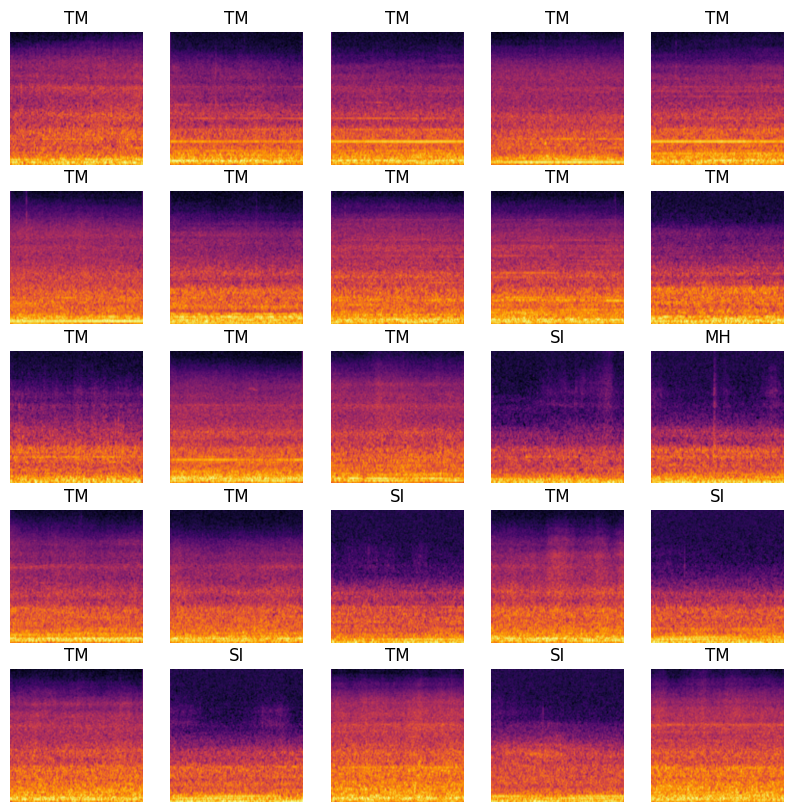

In [35]:
# SHOW MELS

show_batch(image_batch.numpy(), label_batch.numpy())

### Spectogram image analysis and prepare vallidation Mels
- Follows the same preparation as training data

In [38]:
# 20% OF TOTAL MELS 

val_png_filenames = [
    f for f in val_df["png_filename"].values
    if f in os.listdir(MELS_TRVAL_DIR)
]

val_image_count = len(val_png_filenames)
print("PNG en VALIDATION:", val_image_count)

PNG en VALIDATION: 950


In [39]:
# VALIDATION PARAMETERS

VALIDATION_STEPS = int(np.ceil(val_image_count / BATCH_SIZE))
print("VALIDATION steps:", VALIDATION_STEPS)

VALIDATION steps: 15


In [40]:
# MELS PATHS

val_png_paths = [
    os.path.join(MELS_TRVAL_DIR, f)
    for f in val_png_filenames
]

val_list_ds = tf.data.Dataset.from_tensor_slices(val_png_paths)

print("Ejemplos VALIDACIÓN PNG:")
for f in val_list_ds.take(5):
    print(f.numpy().decode())

Ejemplos VALIDACIÓN PNG:
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb\001_29_P1.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb\001_46_P1.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb\001_33_P1.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb\001_73_P1.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_val_mels_pb\001_04_P1.png


In [41]:
# BUILD CORRESPONDENCE BETWEEN PNGs AND LABELS
# Set `num_parallel_calls` so multiple images are loaded/processed in parallel.

val_labeled_ds = val_list_ds.map(
    lambda p: load_png_and_label(p, val_label_lookup),
    num_parallel_calls=AUTOTUNE
)

In [42]:
# EXAMPLE OF CORRESPONDENCE OBTAINED

for img, lab in val_labeled_ds.take(1):
    print("Image shape:", img.numpy().shape)
    print("Label:", lab.numpy())

Image shape: (224, 224, 3)
Label: [1. 0. 0. 0. 0. 0. 0. 0. 0.]


In [43]:
# PREPARE ITERATIONS OVER VALIDATION MELS

validation_ds = val_labeled_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
image_batch, label_batch = next(iter(validation_ds))

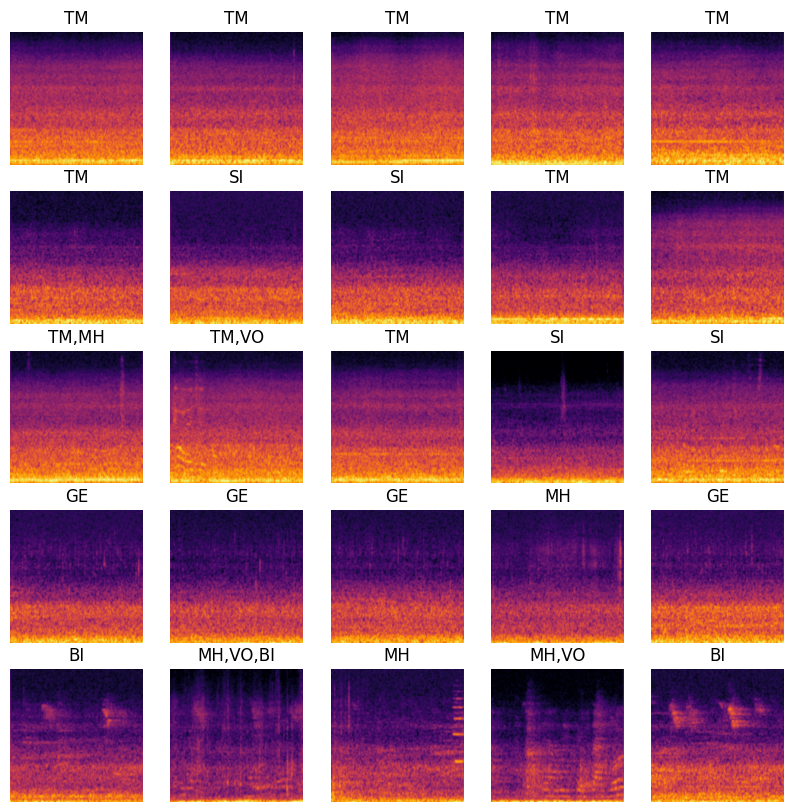

In [44]:
# SHOW MELS

show_batch(image_batch.numpy(), label_batch.numpy())

In [45]:
# NOW WE HAVE TRAINING AND VALIDATION DATA PREPARED:
print(validation_ds)
print(train_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 9), dtype=tf.float32, name=None))>
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 9), dtype=tf.float32, name=None))>


# 2. CNN training: phase 1

- Fine tuning classifier only

In [35]:
# IMAGE SIZE: here 224 is default MobileNet x, y with 3 bands (RGB)

IMG_SIZE = 224
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 3)

In [36]:
# LOAD MOBILENET V2 - IMAGENET

base_model_output = MobileNetV2(input_shape=(224,224,3), include_top=False, weights="imagenet")
base_model_output.trainable = False # freeze backbone

for i, layer in enumerate(base_model_output.layers, start=1):
    print(f"{i:03d} | {layer.__class__.__name__}")

001 | InputLayer
002 | Conv2D
003 | BatchNormalization
004 | ReLU
005 | DepthwiseConv2D
006 | BatchNormalization
007 | ReLU
008 | Conv2D
009 | BatchNormalization
010 | Conv2D
011 | BatchNormalization
012 | ReLU
013 | ZeroPadding2D
014 | DepthwiseConv2D
015 | BatchNormalization
016 | ReLU
017 | Conv2D
018 | BatchNormalization
019 | Conv2D
020 | BatchNormalization
021 | ReLU
022 | DepthwiseConv2D
023 | BatchNormalization
024 | ReLU
025 | Conv2D
026 | BatchNormalization
027 | Add
028 | Conv2D
029 | BatchNormalization
030 | ReLU
031 | ZeroPadding2D
032 | DepthwiseConv2D
033 | BatchNormalization
034 | ReLU
035 | Conv2D
036 | BatchNormalization
037 | Conv2D
038 | BatchNormalization
039 | ReLU
040 | DepthwiseConv2D
041 | BatchNormalization
042 | ReLU
043 | Conv2D
044 | BatchNormalization
045 | Add
046 | Conv2D
047 | BatchNormalization
048 | ReLU
049 | DepthwiseConv2D
050 | BatchNormalization
051 | ReLU
052 | Conv2D
053 | BatchNormalization
054 | Add
055 | Conv2D
056 | BatchNormalization
057 |

In [37]:
# BACKBONE LAYERS
# Let's take a look to see how many layers are in the base model
print("Layers number in base model:", len(base_model_output.layers))

Layers number in base model: 154


In [38]:
# EXTRACT CHARACTERISTICS

feature_batch = base_model_output(image_batch)
print("Shape characteristics:", feature_batch.shape)

Shape characteristics: (64, 7, 7, 1280)


In [39]:
# ADD GlobalAveragePooling2D

global_average_layer = keras.layers.GlobalAveragePooling2D()
feature_batch_avg = global_average_layer(feature_batch)
print("After GAP:", feature_batch_avg.shape)

After GAP: (64, 1280)


In [40]:
# ADD BatchNorm → Dense(ReLU) → Dropout → Prediction layer

batch_norm_layer = keras.layers.BatchNormalization()
dense_layer = keras.layers.Dense(1024, activation="relu")
dropout_layer = keras.layers.Dropout(0.5)
prediction_layer = keras.layers.Dense(N_CLASSES, activation=None)

In [41]:
# COMPILE NEW LAYERS: POOLING + DENSE LAYER

model = keras.Sequential([
    base_model_output,
    global_average_layer,
    batch_norm_layer,
    dense_layer,
    dropout_layer,
    prediction_layer
])

In [42]:
# COMPILE CLASSIFIER

loss_fn = FocalLossMultilabel(alpha=alpha, gamma=2.0)
base_learning_rate = 0.0001

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=base_learning_rate),
    loss=loss_fn,
    metrics=[
        keras.metrics.BinaryAccuracy(),
        keras.metrics.Recall(name="recall"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.AUC(multi_label=True, name="auc")
    ]
)

In [43]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         9,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,584,073 (13.67 MB)

 Trainable params: 1,323,529 (5.05 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [44]:
# TRAINABLE PARAMETERS

len(model.trainable_variables)

6

In [45]:
# CALLBACKS

# Checkpoints that saves the model's weights as a checkpoint for phase 1

checkpoint_cb_1 = ModelCheckpoint(
    filepath=BEST_MODEL_PATH_K_1,     
    save_best_only=True,      
    save_weights_only=False,         
    monitor="val_loss",
    mode="min",
    verbose=1
)

In [46]:
# INITIAL EVALUATION

results = model.evaluate(validation_ds, return_dict=True)

for k, v in results.items():
    print(f"{k}: {v:.4f}")


15/15 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - auc: 0.4849 - binary_accuracy: 0.6540 - loss: 2.4582 - precision: 0.1818 - recall: 0.3545
auc: 0.4849
binary_accuracy: 0.6540
loss: 2.4582
precision: 0.1818
recall: 0.3545


In [47]:
# TRAINING JUST IN THE CLASSIFIER

initial_epochs = 10

history = model.fit(
    train_ds,
    epochs=initial_epochs,
    validation_data=validation_ds,
    callbacks=[checkpoint_cb_1]
)

print("Fine-tuning phase 1 completed.")
print("Best checkpoint saved in:")
print(BEST_MODEL_PATH_K_1)

Epoch 1/10


291/291 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - auc: 0.5706 - binary_accuracy: 0.8079 - loss: 1.8255 - precision: 0.3259 - recall: 0.2191
Epoch 1: val_loss improved from None to 0.93139, saving model to C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_pb_h_1\best_model_finetuned.keras

Epoch 1: finished saving model to C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_pb_h_1\best_model_finetuned.keras
291/291 ━━━━━━━━━━━━━━━━━━━━ 465s 2s/step - auc: 0.5849 - binary_accuracy: 0.8184 - loss: 1.8267 - precision: 0.3477 - recall: 0.1886 - val_auc: 0.6714 - val_binary_accuracy: 0.8497 - val_loss: 0.9314 - val_precision: 0.5623 - val_recall: 0.1197
Epoch 2/10
291/291 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - auc: 0.6622 - binary_accuracy: 0.8519 - loss: 1.1483 - precision: 0.5280 - recall: 0.2414
Epoch 2: val_loss did not improve from 0.93139
291/291 ━━━━━━━━━━━━━━━━━━━━ 440s 2s/step - auc: 0.6489 - binary_accuracy: 0.8449 - loss: 1.2580 - precision: 0.5053 - recall: 0.2244 - 

In [48]:
# plot parameters
SAVE_DPI = 300
TRAIN_COLOR = "#ff6ec7"   
VAL_COLOR   = "#7f00ff"  

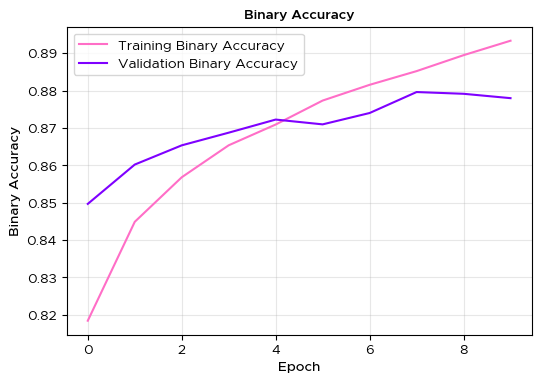

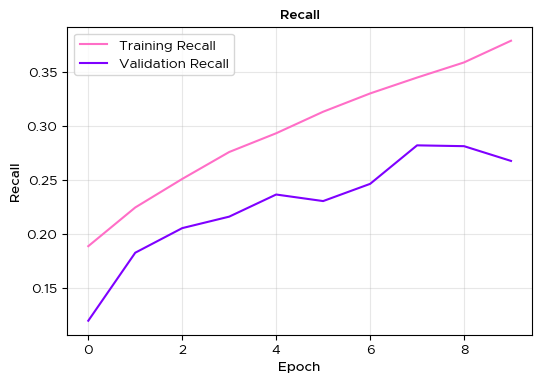

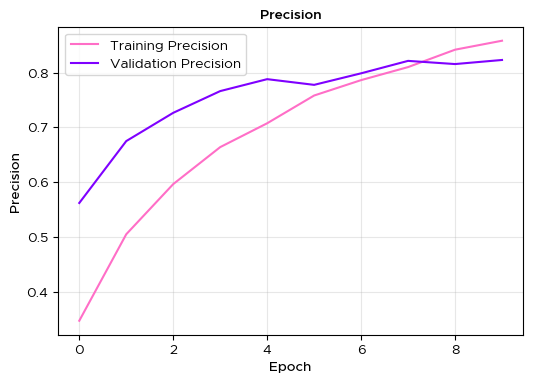

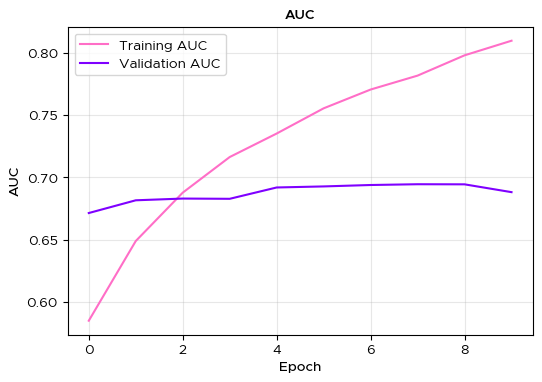

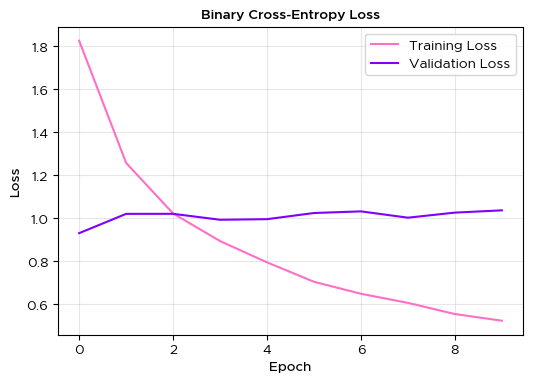

In [49]:
# extract metrics 
acc        = history.history.get("binary_accuracy", [])
val_acc    = history.history.get("val_binary_accuracy", [])

recall     = history.history.get("recall", [])
val_recall = history.history.get("val_recall", [])

precision      = history.history.get("precision", [])
val_precision  = history.history.get("val_precision", [])

auc        = history.history.get("auc", [])
val_auc    = history.history.get("val_auc", [])

loss      = history.history["loss"]
val_loss  = history.history["val_loss"]

# generate plots 
plot_metric(acc, val_acc, "Binary Accuracy", "Binary Accuracy", "binary_accuracy.png")
plot_metric(recall, val_recall, "Recall", "Recall", "recall.png")
plot_metric(precision, val_precision, "Precision", "Precision", "precision.png")
plot_metric(auc, val_auc, "AUC", "AUC", "auc.png")
plot_metric(loss, val_loss, "Binary Cross-Entropy Loss", "Loss", "loss.png")

In [50]:
# load model: phase 1

model_1 = tf.keras.models.load_model(BEST_MODEL_PATH_K_1)

print("✅ Model 1 loaded from:", BEST_MODEL_PATH_K_1)

✅ Model 1 loaded from: C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_pb_h_1\best_model_finetuned.keras


In [51]:
# inference

logits = model_1.predict(validation_ds, verbose=1)
probs = tf.nn.sigmoid(logits).numpy()
y_true = np.concatenate(
    [labels.numpy() for _, labels in validation_ds],
    axis=0
)

print("Shapes:")
print("probs:", probs.shape)
print("y_true:", y_true.shape)

15/15 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step
Shapes:
probs: (950, 9)
y_true: (950, 9)


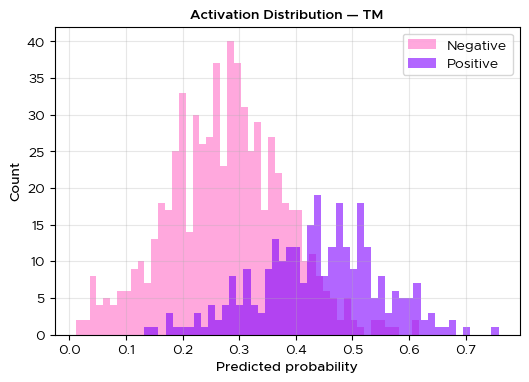

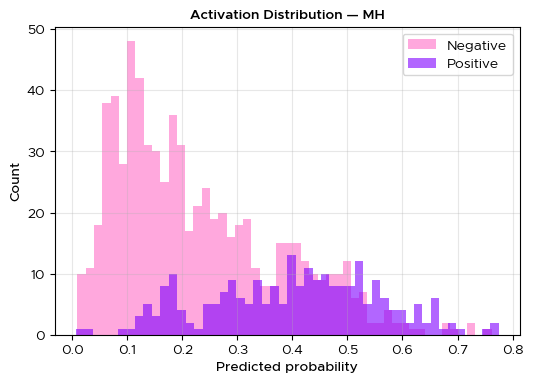

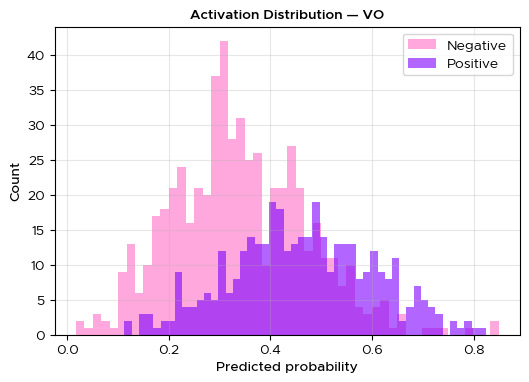

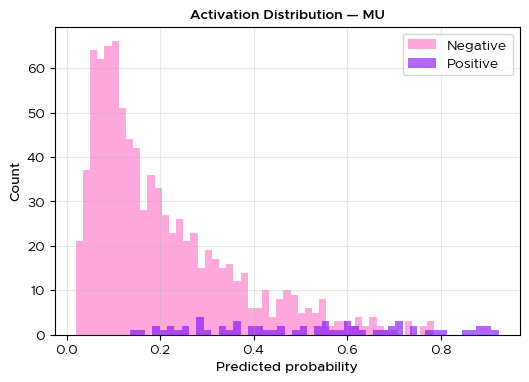

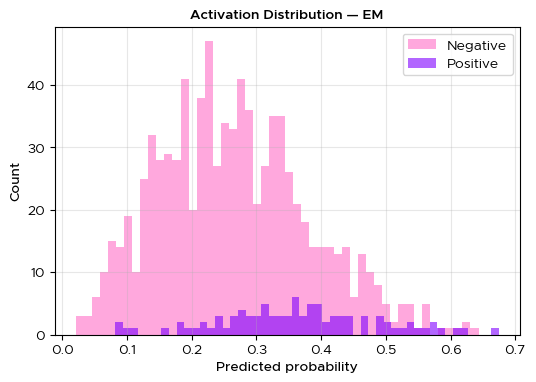

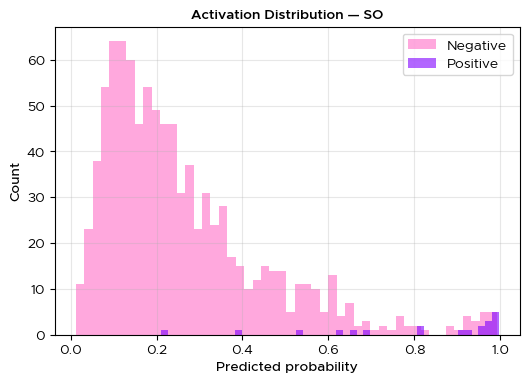

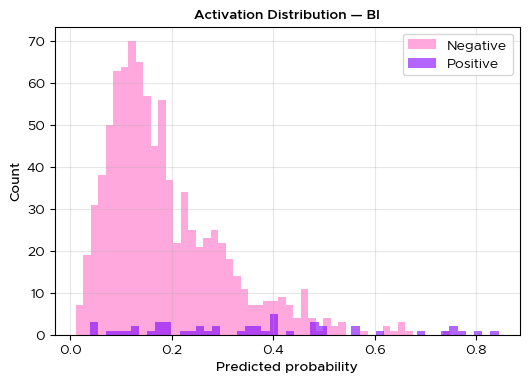

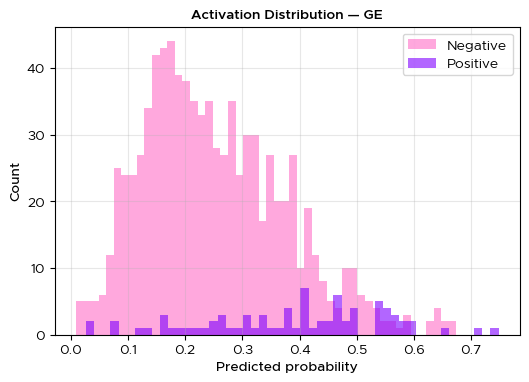

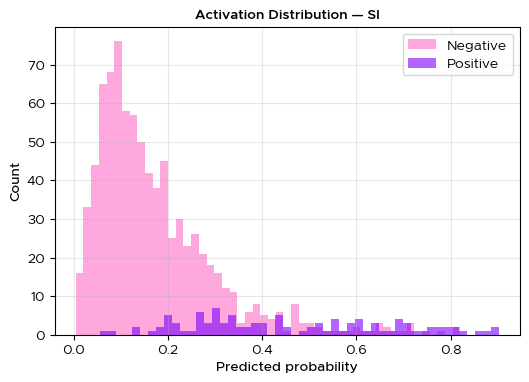

In [52]:
# probabilities distribution by class

for i, cls in enumerate(CLASS_NAMES):

    pos = probs[y_true[:, i] == 1, i]
    neg = probs[y_true[:, i] == 0, i]

    plot_probability_distribution(
        pos_probs=pos,
        neg_probs=neg,
        class_name=cls,
        filename=f"probability_distribution_{cls}_1.png"
    )

In [53]:
# separation by class

stats = []

for i, cls in enumerate(CLASS_NAMES):
    pos = probs[y_true[:, i] == 1, i]
    neg = probs[y_true[:, i] == 0, i]

    stats.append({
        "class": cls,
        "positives": len(pos),
        "pos_mean": pos.mean() if len(pos) else np.nan,
        "neg_mean": neg.mean(),
        "separation": (pos.mean() - neg.mean()) if len(pos) else np.nan
    })

stats_df = pd.DataFrame(stats).sort_values("separation", ascending=False)
stats_df

,class,positives,pos_mean,neg_mean,separation
5,SO,20,0.816083,0.261480,0.554603
3,MU,64,0.515566,0.204242,0.311324
8,SI,105,0.462553,0.172731,0.289822
6,BI,49,0.366780,0.185808,0.180973
1,MH,241,0.401452,0.227507,0.173945
0,TM,286,0.440132,0.277166,0.162965
7,GE,78,0.391895,0.251924,0.139970
2,VO,384,0.461614,0.340150,0.121464
4,EM,93,0.364830,0.265660,0.099169


# 3. CNN training: Phase 2

- Fine tuning the base model

In [54]:
# UNFREEZE: update the ability to train the MobileNet base
base_model_output.trainable = True

In [55]:
# Let's take a look to see how many layers are in the base model
print("Number of layers in the base model: ", len(base_model_output.layers))

Number of layers in the base model:  154


In [56]:
# TRAIN CNN FEATURES HERE
# Fine-tune from this layer onwards
fine_tune_at = 135

# Freeze all the layers before the `fine_tune_at` layer
for layer in base_model_output.layers[:fine_tune_at]:
    layer.trainable = False

In [57]:
# REDUCE LEARNING RATE BY FACTOR OF TEN TO DEAL 
second_tr_lr = base_learning_rate/10

In [58]:
# SET UP THE MODEL BUT WITH SECOND LEARNING RATE
model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=second_tr_lr),     # reduce lr by a factor of 10! LR is 0.00001 here then
        loss=loss_fn,
    metrics=[
        keras.metrics.BinaryAccuracy(),
        keras.metrics.Recall(name="recall"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.AUC(multi_label=True, name="auc")
    ]
)

In [59]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         9,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,584,073 (13.67 MB)

 Trainable params: 2,376,009 (9.06 MB)

 Non-trainable params: 1,208,064 (4.61 MB)

In [60]:
# TRAINABLE PARAMETERS

len(model.trainable_variables) # more trainable parameters because we are tuning the base mobilenet now

26

In [61]:
# EPOCHS FOR FINE-TUNING

fine_tune_epochs = 20 # short training period
total_epochs =  initial_epochs + fine_tune_epochs # total training 

In [62]:
# CALLBACKS

# Checkpoints that saves the model's weights as a checkpoint for phase 2

checkpoint_cb_2 = ModelCheckpoint(
    filepath=BEST_MODEL_PATH_K_2,     
    save_best_only=True,      
    save_weights_only=False,         
    monitor="val_loss",
    mode="min",
    verbose=1
)

# early stopping that stop the model's training if loss does not improve after five epochs

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

In [63]:
# TRAINING WITH LAST TWO BLOCKS OF BASE MODEL

history_fine = model.fit(
    train_ds,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1],
    validation_data=validation_ds,
    callbacks=[checkpoint_cb_2, early_stopping]
)

print("Fine-tuning phase 2 completed.")
print("Best checkpoint saved in:")
print(BEST_MODEL_PATH_K_2)

Epoch 10/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - auc: 0.5504 - binary_accuracy: 0.8393 - loss: 1.6613 - precision: 0.3937 - recall: 0.1079
Epoch 10: val_loss improved from None to 2.25260, saving model to C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_pb_h_2\best_model_finetuned.keras

Epoch 10: finished saving model to C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_pb_h_2\best_model_finetuned.keras
291/291 ━━━━━━━━━━━━━━━━━━━━ 698s 2s/step - auc: 0.5605 - binary_accuracy: 0.8341 - loss: 1.8194 - precision: 0.3899 - recall: 0.1146 - val_auc: 0.5898 - val_binary_accuracy: 0.8599 - val_loss: 2.2526 - val_precision: 0.7629 - val_recall: 0.1341
Epoch 11/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - auc: 0.6312 - binary_accuracy: 0.8440 - loss: 1.2921 - precision: 0.4657 - recall: 0.1783
Epoch 11: val_loss improved from 2.25260 to 1.75523, saving model to C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_pb_h_2\best_model_finetuned.keras



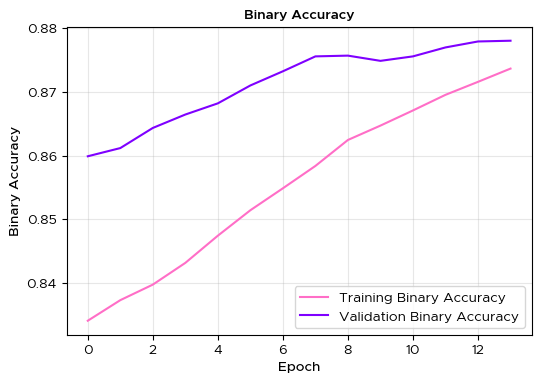

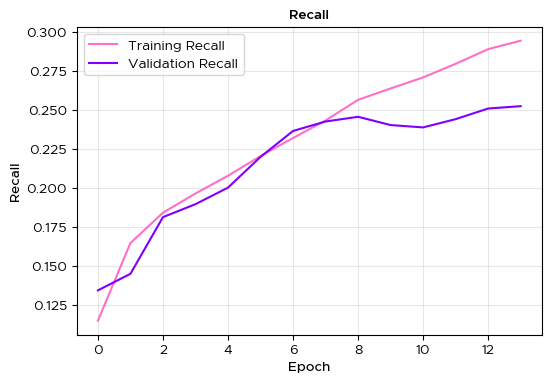

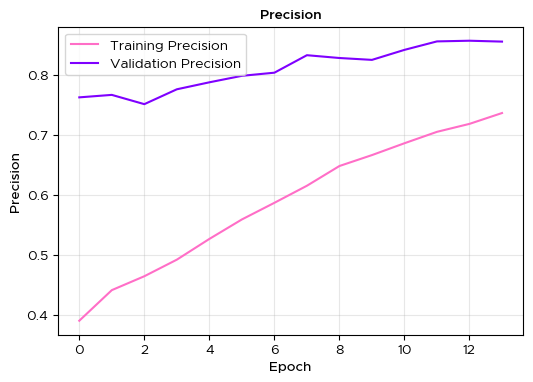

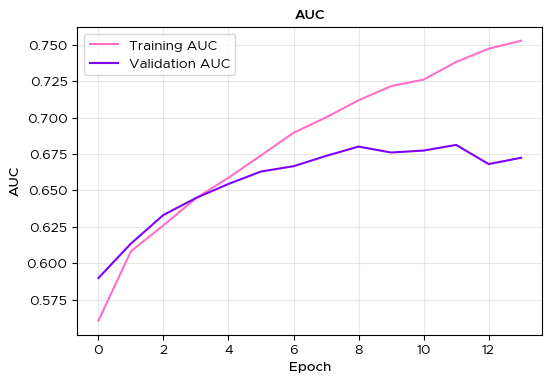

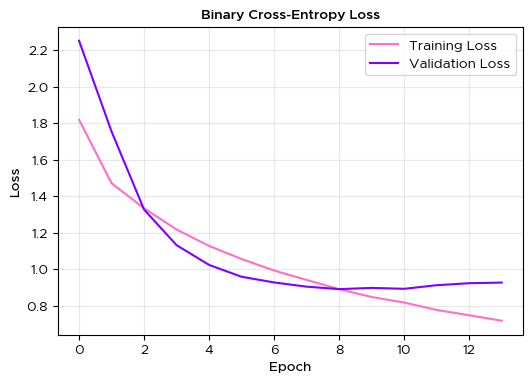

In [69]:
# extract metrics
acc        = history_fine.history.get("binary_accuracy", [])
val_acc    = history_fine.history.get("val_binary_accuracy", [])

recall     = history_fine.history.get("recall", [])
val_recall = history_fine.history.get("val_recall", [])

precision     = history_fine.history.get("precision", [])
val_precision = history_fine.history.get("val_precision", [])

auc        = history_fine.history.get("auc", [])
val_auc    = history_fine.history.get("val_auc", [])

loss     = history_fine.history["loss"]
val_loss = history_fine.history["val_loss"]

# generate plots
plot_metric(acc, val_acc, "Binary Accuracy", "Binary Accuracy", "binary_accuracy_2.png")
plot_metric(recall, val_recall, "Recall", "Recall", "recall_2.png")
plot_metric(precision, val_precision, "Precision", "Precision", "precision_2.png")
plot_metric(auc, val_auc, "AUC", "AUC", "auc_2.png")
plot_metric(loss, val_loss, "Binary Cross-Entropy Loss", "Loss", "loss_2.png")

In [70]:
# load model: phase 2

model_2 = tf.keras.models.load_model(BEST_MODEL_PATH_K_2)

print("✅ Model 2 loaded from:", BEST_MODEL_PATH_K_2)

✅ Model 2 loaded from: C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_pb_h_2\best_model_finetuned.keras


In [71]:
# inference

logits = model_2.predict(validation_ds, verbose=1)
probs = tf.nn.sigmoid(logits).numpy()
y_true = np.concatenate(
    [labels.numpy() for _, labels in validation_ds],
    axis=0
)

print("Shapes:")
print("probs:", probs.shape)
print("y_true:", y_true.shape)

15/15 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step
Shapes:
probs: (950, 9)
y_true: (950, 9)


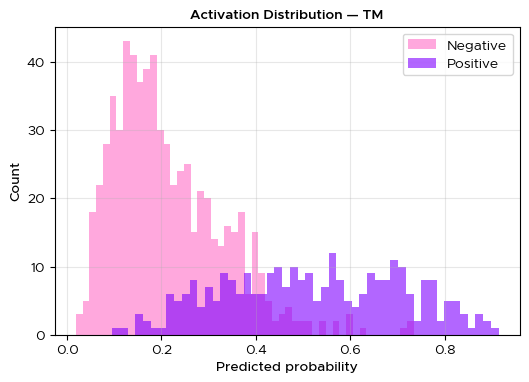

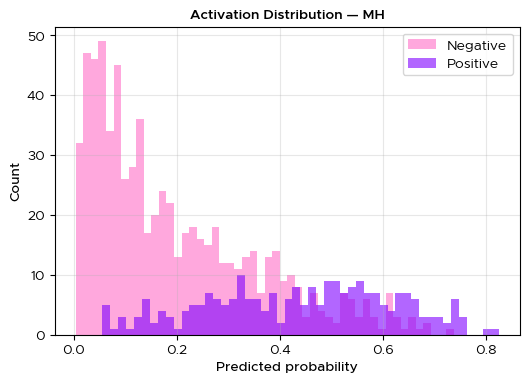

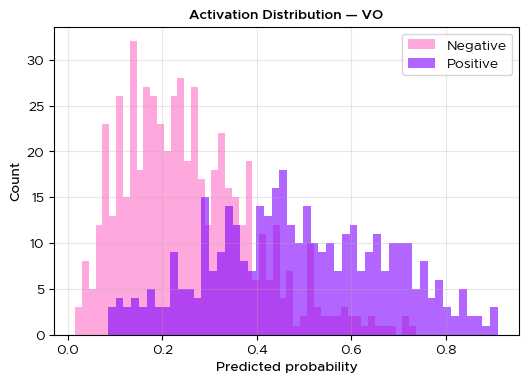

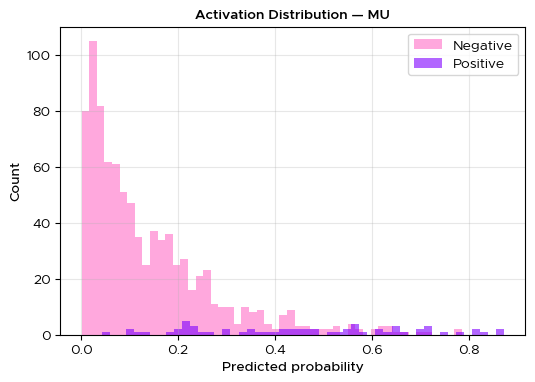

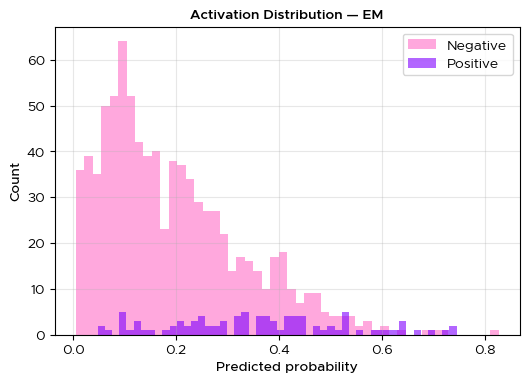

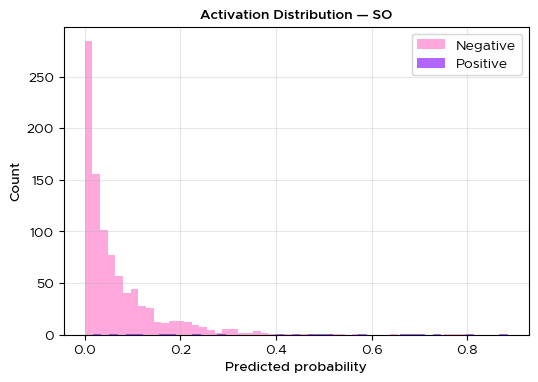

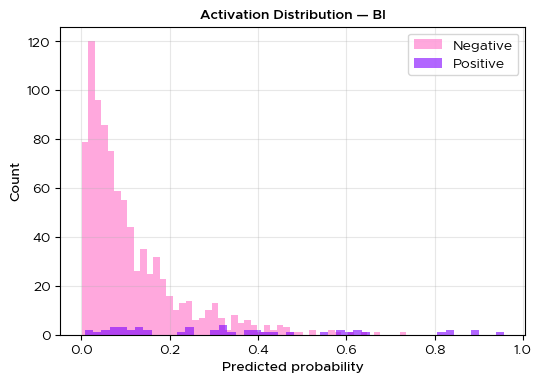

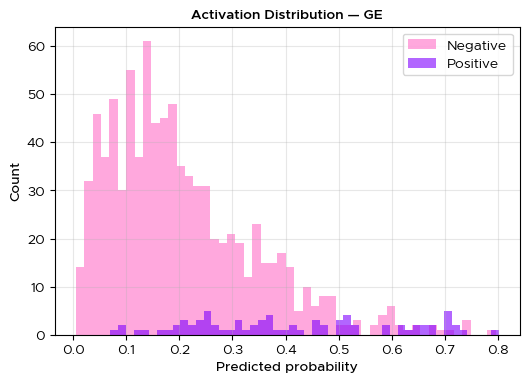

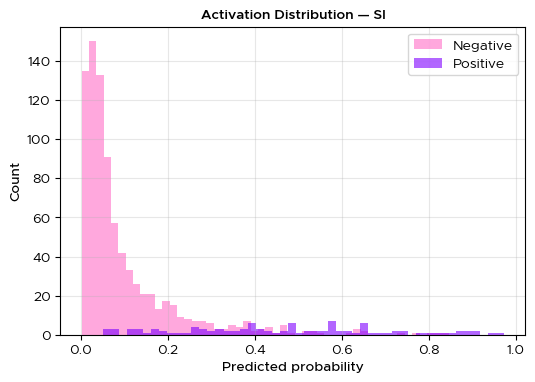

In [72]:
# probabiities distribution by class

for i, cls in enumerate(CLASS_NAMES):

    pos = probs[y_true[:, i] == 1, i]
    neg = probs[y_true[:, i] == 0, i]

    plot_probability_distribution(
        pos_probs=pos,
        neg_probs=neg,
        class_name=cls,
        filename=f"probability_distribution_{cls}_2.png"
    )

In [73]:
# separation by class

stats = []

for i, cls in enumerate(CLASS_NAMES):
    pos = probs[y_true[:, i] == 1, i]
    neg = probs[y_true[:, i] == 0, i]

    stats.append({
        "class": cls,
        "positives": len(pos),
        "pos_mean": pos.mean() if len(pos) else np.nan,
        "neg_mean": neg.mean(),
        "separation": (pos.mean() - neg.mean()) if len(pos) else np.nan
    })

stats_df = pd.DataFrame(stats).sort_values("separation", ascending=False)
stats_df

,class,positives,pos_mean,neg_mean,separation
8,SI,105,0.464561,0.097167,0.367394
5,SO,20,0.428429,0.068025,0.360404
3,MU,64,0.459864,0.139066,0.320798
0,TM,286,0.519124,0.213575,0.305549
1,MH,241,0.435627,0.195766,0.239861
6,BI,49,0.347435,0.109653,0.237782
2,VO,384,0.488136,0.254650,0.233486
7,GE,78,0.415483,0.204892,0.210591
4,EM,93,0.359701,0.193115,0.166586


# 4. Embeddings

In [22]:
# LOAD MODEL

model = keras.models.load_model(BEST_MODEL_PATH_K_2)

In [23]:
# OUR BACKBONE

backbone = model.layers[0]      # MobileNetV2 (Functional)
backbone

<Functional name=mobilenetv2_1.00_224, built=True>

In [24]:
# PARTIALLY BUILD THE MODEL FOR EMBEDDINGS

inputs = backbone.input
x = backbone.output                     # (None, 7, 7, 1280)
x = keras.layers.GlobalAveragePooling2D(name="gap_embedding")(x)

embedding_model = keras.Model(
    inputs=inputs,
    outputs=x,
    name="embedding_model"
)

print("Input shape:", embedding_model.input_shape)
print("Embedding shape:", embedding_model.output_shape)


Input shape: (None, 224, 224, 3)
Embedding shape: (None, 1280)


In [36]:
# TEST BUILT MODEL

x_test = next(iter(train_ds))[0]
z_test = embedding_model.predict(x_test, verbose=0)

print(z_test.shape)

(64, 1280)


In [ ]:
# EXTRACT TRAIN AND VAL EMBEDDINGS (Z = LATENT EMBEDDINGS, Y = REAL LABELS)

Z_train, Y_train = extract_embeddings(train_ds)
Z_val,   Y_val   = extract_embeddings(validation_ds)

print("Train embeddings:", Z_train.shape)
print("Val embeddings:", Z_val.shape)

In [ ]:
# JOIN TRAIN AND VAL EMBEDDINGS

Z = np.vstack([Z_train, Z_val])
Y = np.vstack([Y_train, Y_val])

In [ ]:
# LATENT SPACE DATAFRAME (MELS VS LATEN SPACE DIMENSIONS)

latent_df = pd.DataFrame(Z, columns=[f"z{i}" for i in range(Z.shape[1])])

for i, cls in enumerate(CLASS_NAMES):
    latent_df[cls] = Y[:, i]

latent_df.head()

,z0,z1,z2,z3,z4,z5,z6,z7,z8,z9,...,z1279,TM,MH,VO,MU,EM,SO,BI,GE,SI
0,1.449980,0.239198,0.060300,1.212857,1.848064,0.111624,1.082252,0.391849,0.017614,0.587250,...,0.064955,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.377304,0.000833,1.320479,1.013277,0.028170,0.869840,0.007141,0.000000,0.476978,0.546144,...,0.068143,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.016691,0.000000,0.892830,1.377915,0.034903,0.027858,0.000000,0.770650,0.164084,0.429741,...,0.070889,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.272021,0.029225,0.052516,2.619650,0.000000,0.077824,0.000000,0.825769,0.043307,0.166895,...,0.305334,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.952215,0.098158,0.322691,0.221062,0.000000,0.064457,0.031093,0.121352,0.065252,0.530537,...,0.017268,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# CREATE Uniform Manifold Approximation and Projection (UMAP)

reducer = umap.UMAP(
    n_neighbors=20,
    min_dist=0.2,
    n_components=2,
    random_state=42,
    metric="euclidean"
)

Z_umap = reducer.fit_transform(Z)

latent_df["UMAP1"] = Z_umap[:, 0]
latent_df["UMAP2"] = Z_umap[:, 1]

c:\Users\Acer\Desktop\TSI\U_VNE_CNN\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [ ]:
latent_df["label"] = latent_df.apply(dominant_label, axis=1)

In [ ]:
# UMAP COLOR

palette = {
    "TM": "#ff9f1c",
    "MH": "#000dff",
    "VO": "#ff2e63",
    "MU": "#7f00ff",
    "EM": "#00e5ff",
    "SO": "#ff00ea",
    "BI": "#26FF00",
    "GE": "#e1ff00",
    "SI": "#c77dff",
    "None": "#B9B9B9"
}

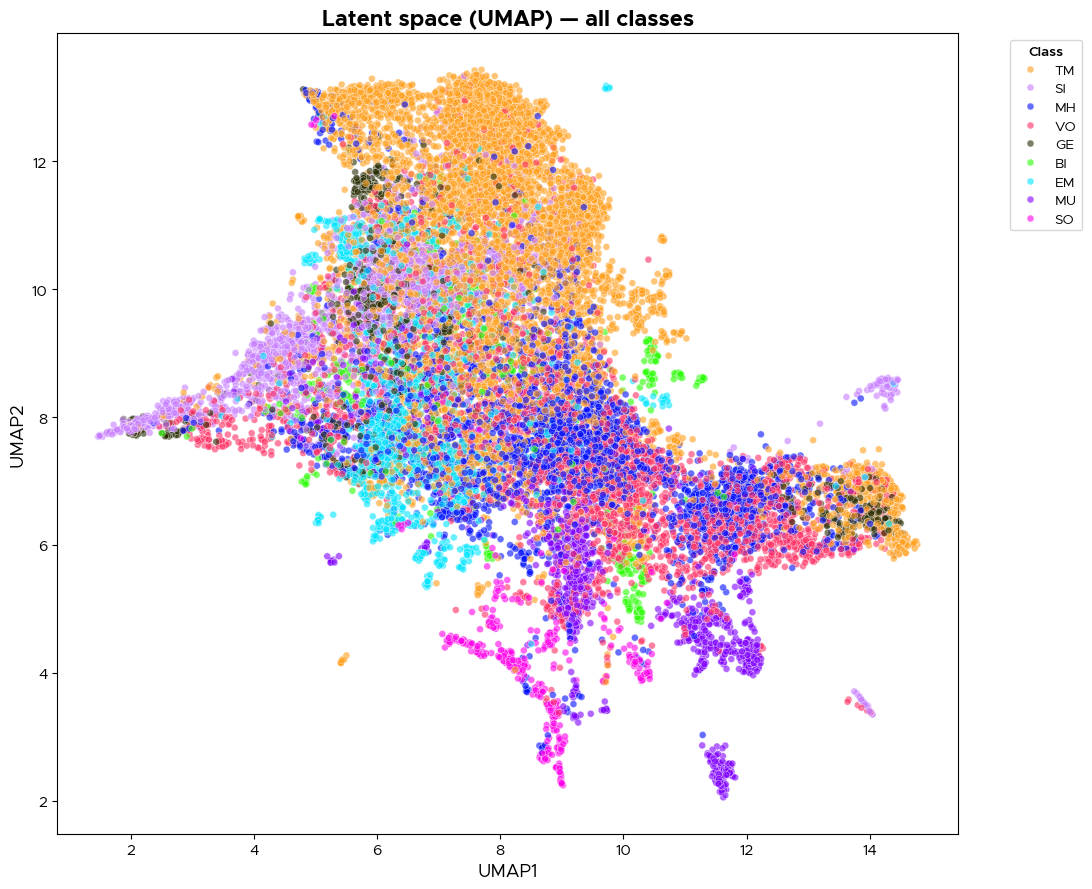

In [ ]:
# PLOT UMAP

plt.figure(figsize=(11, 9))

ax = sns.scatterplot(
    data=latent_df,
    x="UMAP1",
    y="UMAP2",
    hue="label",
    palette=palette,
    alpha=0.6,
    s=25
)

ax.set_title(
    "Latent space (UMAP) — all classes",
    fontproperties=metro["bold"],
    fontsize=16
)

ax.set_xlabel("UMAP1", fontproperties=metro["regular"], fontsize=13)
ax.set_ylabel("UMAP2", fontproperties=metro["regular"], fontsize=13)

for tick in ax.get_xticklabels():
    tick.set_fontproperties(metro["regular"])
    tick.set_fontsize(11)

for tick in ax.get_yticklabels():
    tick.set_fontproperties(metro["regular"])
    tick.set_fontsize(11)

legend = ax.legend(
    title="Class",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    prop=metro["regular"]
)

legend.get_title().set_fontproperties(metro["semibold"])

plt.tight_layout()
plt.show()

In [ ]:
results = []

for cls in CLASS_NAMES:
    idx = CLASS_NAMES.index(cls)
    y = Y[:, idx]

    Z_pos = Z[y == 1]
    Z_neg = Z[y == 0]


    # intra / inter distances
    d_intra = pairwise_distances(Z_pos, Z_pos).mean()
    d_inter = pairwise_distances(Z_pos, Z_neg).mean()

    # latent separability (AUC lineal)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    aucs = []
    for tr, te in skf.split(Z, y):
        clf = LogisticRegression(max_iter=2000)
        clf.fit(Z[tr], y[tr])
        probs = clf.predict_proba(Z[te])[:, 1]
        aucs.append(roc_auc_score(y[te], probs))

    auc = np.mean(aucs)

    # local mixed (k-nearest neighbors)
    nbrs = NearestNeighbors(n_neighbors=2).fit(Z)
    _, inds = nbrs.kneighbors(Z_pos)

    neighbor_labels = []
    for row in inds:
        nb = row[1]
        for j, c in enumerate(CLASS_NAMES):
            if Y[nb, j] == 1:
                neighbor_labels.append(c)

    top_neighbors = dict(Counter(neighbor_labels).most_common(3))

    results.append({
        "class": cls,
        "n_samples": len(Z_pos),
        "d_intra": d_intra,
        "d_inter": d_inter,
        "auc": auc,
        "top_neighbors": top_neighbors
    })

overlap_df = pd.DataFrame(results)
overlap_df

,class,n_samples,d_intra,d_inter,auc,top_neighbors
0,TM,6716,23.916304,24.090435,0.921058,"{'TM': 5533, 'VO': 1659, 'GE': 927}"
1,MH,3666,21.994190,23.329903,0.871348,"{'MH': 2518, 'VO': 2034, 'TM': 564}"
2,VO,7220,22.907070,23.673996,0.901472,"{'VO': 5930, 'MH': 2024, 'TM': 1685}"
3,MU,2028,21.697285,23.624365,0.954615,"{'MU': 1787, 'VO': 746, 'MH': 247}"
4,EM,2141,21.926414,23.207363,0.939254,"{'EM': 1734, 'TM': 779, 'VO': 314}"
5,SO,515,20.055229,23.713522,0.995286,"{'SO': 483, 'MH': 52, 'VO': 35}"
6,BI,1047,22.085291,23.203415,0.953207,"{'BI': 839, 'TM': 328, 'VO': 162}"
7,GE,1889,23.879189,24.021528,0.913150,"{'GE': 1374, 'TM': 905, 'VO': 315}"
8,SI,2177,23.289207,24.096107,0.950710,"{'SI': 1558, 'TM': 272, 'VO': 186}"
